<a href="https://colab.research.google.com/github/yeugeneu/IAT360-CV-13-Cloud-Type-Classifier/blob/Model-Evaluation/Cloud_type_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Preprocessing
We have to convert the dataset into that acceptable by YOLO.
- Heirarchy of folders should be the one accepted by YOLO
- Labels format should be object detection for YOLOv8
```
class x_center y_center width height
```

- Labels files should be .txt files with an object in the image per row

1. Make sure you download and extract the dataset [CloudDataset](https://app.roboflow.com/eugene-yu/cloud-qthye-mirzy/1) forked from [Roboflow Cloud Computer Vision Model dataset](https://universe.roboflow.com/ip2-kbjz5/cloud-qthye/browse?queryText=&pageSize=100&startingIndex=0&browseQuery=true)


2. Rename the folder to 'CloudDataset'

3. Below steps will guide you through converting the original dataset to the folder hierarchy we wish to use


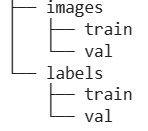

## Import required libraries

In [ ]:
import glob
import os
import random
import shutil
from PIL import Image
import cv2
import matplotlib.pyplot as plt
import pandas as pd

## Re-organize source Dataset images/labels

Load all images and labels located inside the "CloudDataset" folder

In [ ]:
# Set train, validate, and test dataset paths
train_dir_img = 'CloudDataset/train/images'
train_dir_lbl = 'CloudDataset/train/labels'

val_dir_img = 'CloudDataset/valid/images'
val_dir_lbl = 'CloudDataset/valid/labels'

In [ ]:
import os

# Define source directory paths directly
train_dir_img = 'CloudDataset/train/images'
train_dir_lbl = 'CloudDataset/train/labels'

val_dir_img = 'CloudDataset/valid/images'
val_dir_lbl = 'CloudDataset/valid/labels'

test_dir_img = 'CloudDataset/test/images'
test_dir_lbl = 'CloudDataset/test/labels'

# Define directories to clean
dirs_to_clean = [
    (train_dir_img, train_dir_lbl),
    (val_dir_img, val_dir_lbl)
]

seen_bases = set()

for img_dir, lbl_dir in dirs_to_clean:
    if not os.path.exists(img_dir):
        print(f"Directory does not exist, skipping: {img_dir}")
        continue

    files = sorted(os.listdir(img_dir))

    removed_count = 0
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            # Roboflow export formats usually contain '.rf.' before the unique hash
            # e.g., 'Ac-N001_jpg.rf.8c98886d88bb955b60652b2a5f2f42a6.jpg' -> base 'Ac-N001_jpg'
            if '.rf.' in file:
                base_name = file.split('.rf.')[0]
            else:
                base_name = os.path.splitext(file)[0]

            img_path = os.path.join(img_dir, file)

            # Match corresponding label txt file
            label_file = os.path.splitext(file)[0] + '.txt'
            lbl_path = os.path.join(lbl_dir, label_file)

            if base_name in seen_bases:
                # Duplicate found, remove both image and label
                if os.path.exists(img_path):
                    os.remove(img_path)
                if os.path.exists(lbl_path):
                    os.remove(lbl_path)
                removed_count += 1
            else:
                # First instance, keep it
                seen_bases.add(base_name)

    print(f"Cleaned {img_dir}: Kept {len(seen_bases)} unique images, removed {removed_count} augmented instances.")

Cleaned CloudDataset/train/images: Kept 2310 unique images, removed 0 augmented instances.
Cleaned CloudDataset/valid/images: Kept 2521 unique images, removed 0 augmented instances.


Create new root folder called "All_data", with 2 child folders "images" and "labels"

In [ ]:
os.makedirs('All_data/images')
os.makedirs('All_data/labels')

Copy the label txt files and image jpg files to the new folders created

In [ ]:
#set the paths to labels and images directory for All data
label_dir= "All_data/labels"
image_dir= "All_data/images"

In [ ]:
# Source directories mapped to their target categories
image_sources = [train_dir_img, val_dir_img]
label_sources = [train_dir_lbl, val_dir_lbl]

# Copy and process all images to image_dir
for src_dir in image_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                try:
                    img_path = os.path.join(src_dir, file)
                    image = Image.open(img_path)
                    image = image.convert("RGB")
                    base, ext = os.path.splitext(file)
                    # Replace '.' with '-' in the filename base
                    safe_base = base.replace(".", "-")
                    new_filename = safe_base + ".jpg"
                    image.save(os.path.join(image_dir, new_filename), "JPEG")
                except Exception as e:
                    print(f"Error processing image {file}: {e}")

# Copy all label files to label_dir
for src_dir in label_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith(".txt"):
                base, ext = os.path.splitext(file)
                # Replace '.' with '-' in the filename base
                safe_base = base.replace(".", "-")
                new_filename = safe_base + ext
                shutil.copy(os.path.join(src_dir, file), os.path.join(label_dir, new_filename))

## Check the Source Dataset

Take a look at the first 4 images in the "Final_data/images" folder to make sure the images are moved correctly

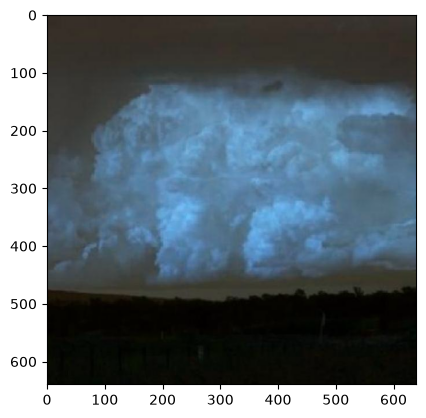

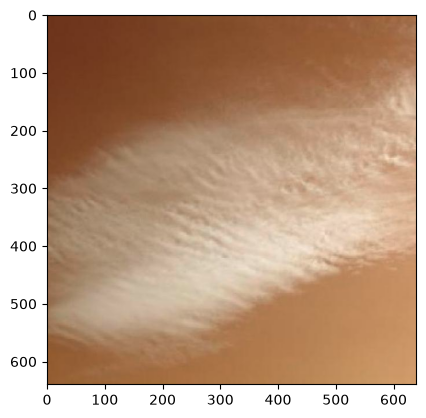

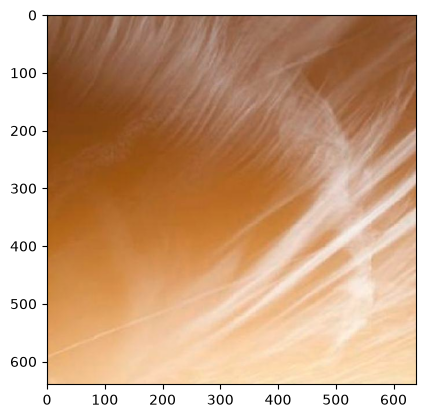

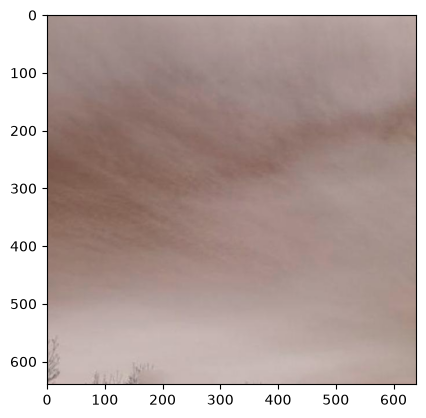

In [ ]:
#visualize first four sample images from train data
for idx, image in enumerate(os.listdir(os.path.join(image_dir))):
    img = cv2.imread(os.path.join(image_dir, image), 1)
    plt.imshow(img)
    plt.show()

    if idx == 3:
        break

class_name
Stratocumulus    344
Cirrostratus     288
Nimbostratus     274
Cirrocumulus     260
Cumulonimbus     235
Altocumulus      219
Contrails        205
Stratus          204
Altostratus      188
Cumulus          178
Cirrus           140
Name: count, dtype: int64
Total Instances (Bounding Boxes): 2535
Total Images (Unique annotated files): 2521


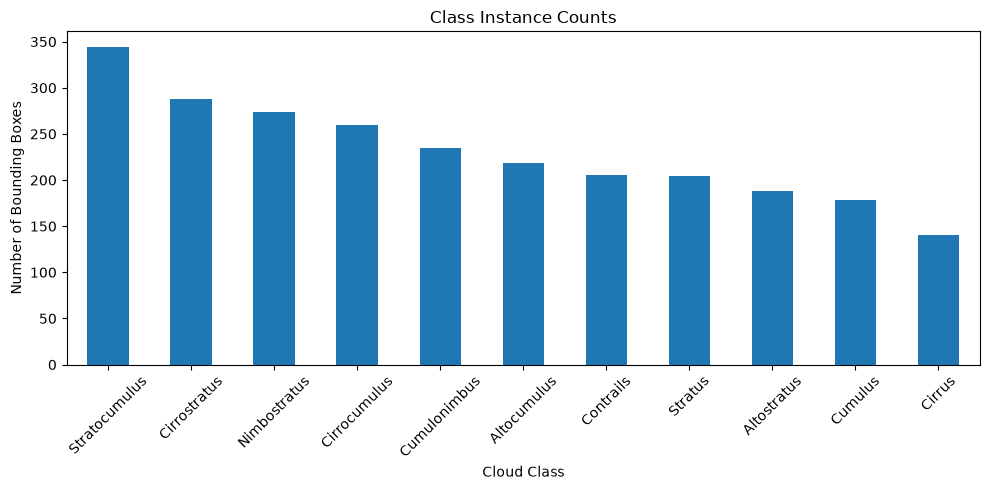

In [ ]:
# 1. Define your class mapping dictionary
class_map = {
    0: "Altocumulus",
    1: "Altostratus",
    2: "Cirrocumulus",
    3: "Cirrostratus",
    4: "Cirrus",
    5: "Contrails",
    6: "Cumulonimbus",
    7: "Cumulus",
    8: "Nimbostratus",
    9: "Stratocumulus",
    10: "Stratus"
}

# 2. Gather label annotation files
labels_dir = "All_data/labels"
annotation_files = glob.glob(os.path.join(labels_dir, "*.txt"))

records = []
for file in annotation_files:
    with open(file, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if parts:
                records.append(int(parts[0]))

# Create DataFrame
df = pd.DataFrame(records, columns=['class_id'])

# Map class IDs to names
df['class_name'] = df['class_id'].map(class_map)

# Value counts table
print(df['class_name'].value_counts())

# Compute totals
total_instances = len(df)
total_images = len(annotation_files)

# Print requested metrics in bold
print(f"\033[1mTotal Instances (Bounding Boxes): {total_instances}\033[0m")
print(f"\033[1mTotal Images (Unique annotated files): {total_images}\033[0m")

# Plot distribution
df['class_name'].value_counts().plot(kind='bar', figsize=(10, 5), title="Class Instance Counts")
plt.xlabel("Cloud Class")
plt.ylabel("Number of Bounding Boxes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Split the source data
Split into 80-20 train-validation sets and re-organize the data into correct sub-folders

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Load the sorted lists of all images and matching labels
# Sorting ensures that images and labels pair up correctly (e.g., image[i] matches label[i])
images_dir = "All_data/images"
labels_dir = "All_data/labels"

# Get all file names and sort them alphabetically
image_files = sorted(os.listdir(images_dir))
label_files = sorted(os.listdir(labels_dir))

# Double check we are matching base names (e.g., image_01.jpg maps to image_01.txt)
# We'll filter to make sure we only split perfectly matching image-label pairs
valid_images = []
valid_labels = []

for img in image_files:
    base_name = os.path.splitext(img)[0]
    label_name = f"{base_name}.txt"
    if label_name in label_files:
        valid_images.append(os.path.join(images_dir, img))
        valid_labels.append(os.path.join(labels_dir, label_name))

# 2. Split into 80% train+validation and 20% test set
X_train, X_validation, y_train, y_validation = train_test_split(
    valid_images,
    valid_labels,
    test_size=0.20,
    random_state=42
)

print(f"Split completed:")
print(f"  - Train set size: {len(X_train)} pairs")
print(f"  - Validation set size: {len(X_validation)} pairs")


Split completed:
  - Train set size: 2016 pairs
  - Validation set size: 505 pairs


In [ ]:
# Define the target subdirectories
splits = ['train', 'val']
for split in splits:
    os.makedirs(os.path.join("All_data/images", split), exist_ok=True)
    os.makedirs(os.path.join("All_data/labels", split), exist_ok=True)

# Helper function to move a list of files to their respective folder
def move_files(file_paths, destination_folder):
    for path in file_paths:
        if os.path.exists(path):
            filename = os.path.basename(path)
            shutil.move(path, os.path.join(destination_folder, filename))

# Move image sets
move_files(X_train, "All_data/images/train")
move_files(X_validation, "All_data/images/val")

# Move label sets
move_files(y_train, "All_data/labels/train")
move_files(y_validation, "All_data/labels/val")

# Verify counts in new structured folders
print("\nPhysical Split Verification:")
for split in splits:
    img_count = len(os.listdir(os.path.join("All_data/images", split)))
    lbl_count = len(os.listdir(os.path.join("All_data/labels", split)))
    print(f"  - {split.capitalize()} Set: {img_count} images | {lbl_count} labels")



Physical Split Verification:
  - Train Set: 2016 images | 2016 labels
  - Val Set: 505 images | 505 labels


## Organize group member images and Move them into test folder as test set

Download the images collected from all 4 group members ([FirstName]_Cloud_Data_Labeled) located in this link https://1sfu-my.sharepoint.com/:f:/r/personal/yya6_sfu_ca/Documents/CV%20Project%20Group%2013?d=w11d6cbb929af48b29ee060bcf9c1bf78&csf=1&web=1&e=WJnLSs


In [ ]:
# creates Members_Dataset and moves every folder ending in _CloudData_Labeled
import os, shutil

os.makedirs("Members_Dataset", exist_ok=True)

for name in os.listdir("."):
    if name.endswith("_CloudData_Labeled") and os.path.isdir(name):
        shutil.move(name, os.path.join("Members_Dataset", name))
        print("moved", name)

# show what's inside so you can check the structure
for name in os.listdir("Members_Dataset"):
    print(name, "->", os.listdir(os.path.join("Members_Dataset", name)))

Dalena_CloudData_Labeled -> ['classes.txt', '.DS_Store', 'images', 'labels', 'notes.json']
Marielle_CloudData_Labeled -> ['classes.txt', '.DS_Store', 'images', 'labels', 'notes.json']
Eugene_CloudData_Labeled -> ['classes.txt', '.DS_Store', 'images', 'labels', 'notes.json']
Martina_CloudData_Labeled -> ['classes.txt', '.DS_Store', 'images', 'labels', 'notes.json']


In [ ]:
# Set all paths to the dataset
eugene_dir_img = 'Members_Dataset/Eugene_CloudData_Labeled/images'
eugene_dir_lbl = 'Members_Dataset/Eugene_CloudData_Labeled/labels'

dalena_dir_img = 'Members_Dataset/Dalena_CloudData_Labeled/images'
dalena_dir_lbl = 'Members_Dataset/Dalena_CloudData_Labeled/labels'

martina_dir_img = 'Members_Dataset/Martina_CloudData_Labeled/images'
martina_dir_lbl = 'Members_Dataset/Martina_CloudData_Labeled/labels'

marielle_dir_img = 'Members_Dataset/Marielle_CloudData_Labeled/images'
marielle_dir_lbl = 'Members_Dataset/Marielle_CloudData_Labeled/labels'

Copy the label txt files and image jpg files to the new folders created

In [ ]:
#set the paths to labels and images directory for test data
test_label_dir= "All_data/labels/test"
test_image_dir= "All_data/images/test"

os.makedirs(os.path.join("All_data/labels/test"), exist_ok=True)
os.makedirs(os.path.join("All_data/images/test"), exist_ok=True)

Every image from every member gets converted to RGB .jpg and saved into All_data/images/test. Every label .txt from every member gets copied into All_data/labels/test

In [ ]:
# Source directories mapped to their target categories
image_sources = [eugene_dir_img, dalena_dir_img, martina_dir_img, marielle_dir_img]
label_sources = [eugene_dir_lbl, dalena_dir_lbl, martina_dir_lbl, marielle_dir_lbl]

# Copy and process all images to test_image_dir
for src_dir in image_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                try:
                    img_path = os.path.join(src_dir, file)
                    image = Image.open(img_path)
                    image = image.convert("RGB")
                    new_filename = os.path.splitext(file)[0] + ".jpg"
                    image.save(os.path.join(test_image_dir, new_filename), "JPEG")
                except Exception as e:
                    print(f"Error processing image {file}: {e}")

# Copy all label files to test_label_dir
for src_dir in label_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith(".txt"):
                shutil.copy(os.path.join(src_dir, file), os.path.join(test_label_dir, file))

## Check for final file structures

Each set should contain the same amount of images and labels

In [ ]:
train_img = "All_data/images/train"
train_lbl = "All_data/labels/train"
val_img = "All_data/images/val"
val_lbl = "All_data/labels/val"
test_img = "All_data/images/test"
test_lbl = "All_data/labels/test"

# Group the folder pairs together for verification
pairs = [
    ("Train Set", train_img, train_lbl),
    ("Validation Set", val_img, val_lbl),
    ("Test Set", test_img, test_lbl)
]

for name, img_folder, lbl_folder in pairs:
    num_images = len([f for f in os.listdir(img_folder) if os.path.isfile(os.path.join(img_folder, f))])
    num_labels = len([f for f in os.listdir(lbl_folder) if os.path.isfile(os.path.join(lbl_folder, f))])
    print(f"{name}: {num_images} images | {num_labels} labels")
    assert num_images == num_labels, f"Mismatch in {name}! Images: {num_images}, Labels: {num_labels}"

Train Set: 2016 images | 2016 labels
Validation Set: 505 images | 505 labels
Test Set: 120 images | 120 labels


Randomly pick 2 data from each of train and val sets to visualize

Visualizing from train set: Cb-N020_jpg-rf-74bfda4eb85c33d02f2f83c1c13bacd7.jpg


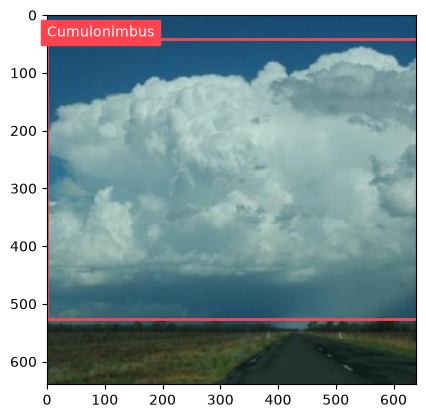

Visualizing from train set: Ct-N073_jpg-rf-41c99a8d5c452661d1f34817df78ac32.jpg


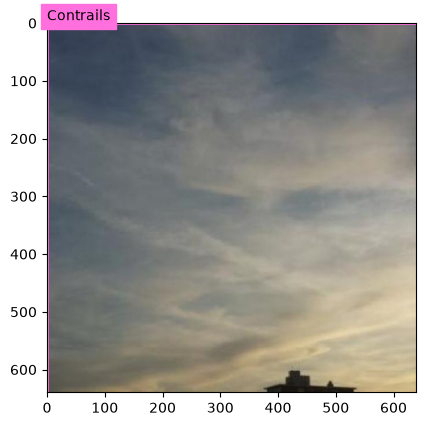

Visualizing from val set: St-N167_jpg-rf-eaeab487210b1f665716ca0061ddb876.jpg


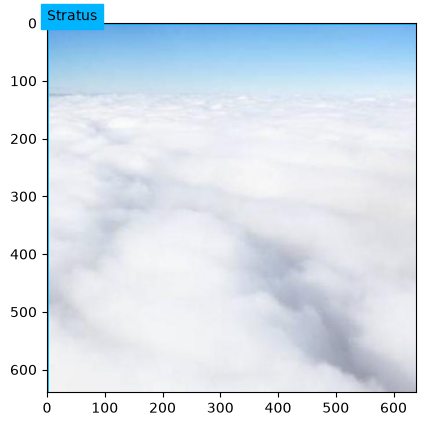

Visualizing from val set: Cc-N148_jpg-rf-1c702336386716387f8c6c66d16abdde.jpg


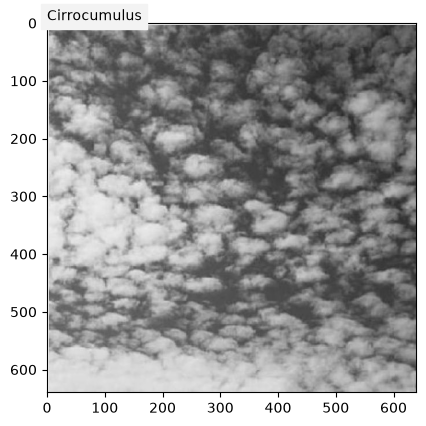

In [ ]:
from ultralytics.data.utils import visualize_image_annotations
import os
import random

# define the class map
class_map = {
    0: "Altocumulus",
    1: "Altostratus",
    2: "Cirrocumulus",
    3: "Cirrostratus",
    4: "Cirrus",
    5: "Contrails",
    6: "Cumulonimbus",
    7: "Cumulus",
    8: "Nimbostratus",
    9: "Stratocumulus",
    10: "Stratus"
}

# Splits to choose from (only train and val)
splits = ["train", "val"]

for split in splits:
    img_dir = f"All_data/images/{split}"
    lbl_dir = f"All_data/labels/{split}"

    if os.path.exists(img_dir) and os.path.exists(lbl_dir):
        # Get a list of all image files in this split
        image_files = [f for f in os.listdir(img_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))]

        if image_files:
            # Pick 2 random images from this split
            random_images = random.sample(image_files, min(2, len(image_files)))

            for random_image in random_images:
                # Construct matching image and label paths
                base_name = os.path.splitext(random_image)[0]
                random_image_path = os.path.join(img_dir, random_image)
                random_label_path = os.path.join(lbl_dir, f"{base_name}.txt")

                # Visualize
                print(f"Visualizing from {split} set: {random_image}")
                visualize_image_annotations(
                    random_image_path,
                    random_label_path,
                    class_map,
                )
        else:
            print(f"No images found in {img_dir}")
    else:
        print(f"Directory does not exist for split: {split}")

Randomly pick 4 images from test set to visualize the annotation

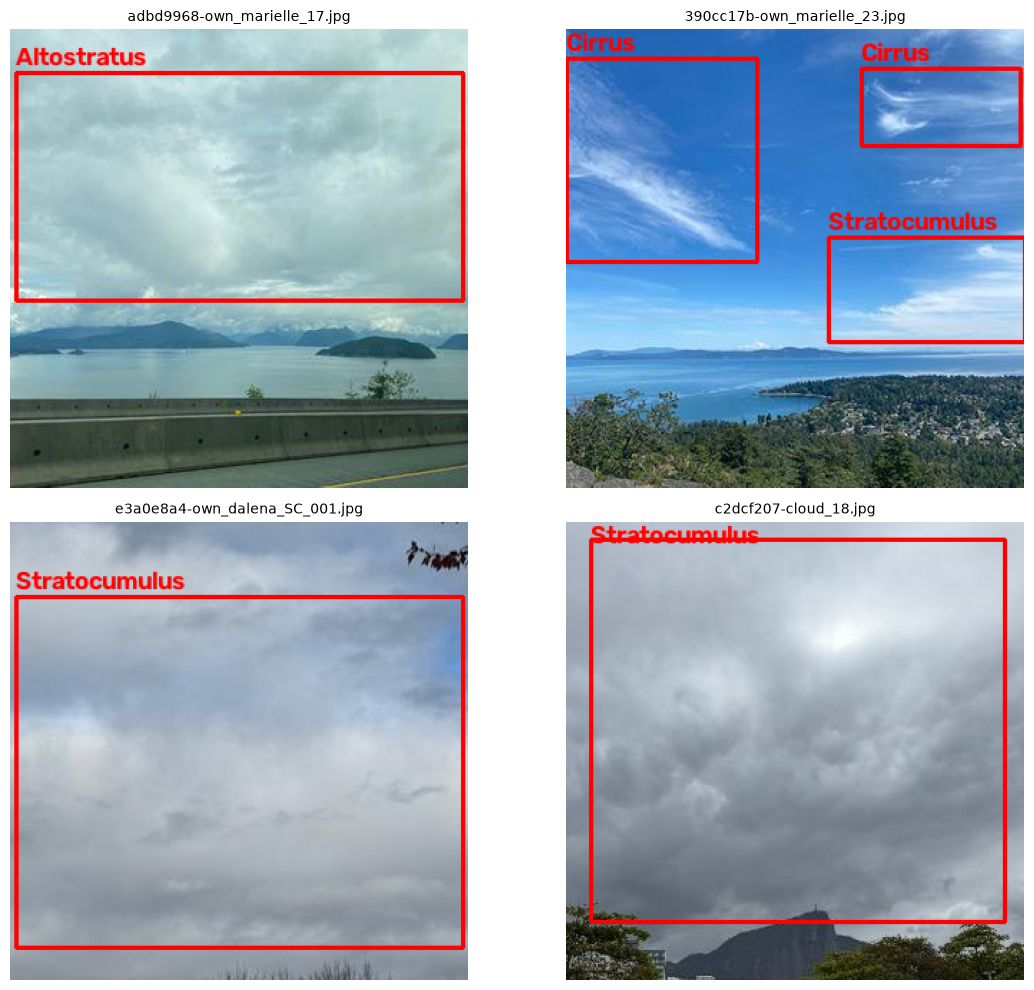

In [ ]:
import os
import random
import cv2
import matplotlib.pyplot as plt
from PIL import Image

# Define paths
test_images_dir = "All_data/images/test"
test_labels_dir = "All_data/labels/test"

# Define the class map to translate IDs to class names
class_map = {
    0: "Altocumulus",
    1: "Altostratus",
    2: "Cirrocumulus",
    3: "Cirrostratus",
    4: "Cirrus",
    5: "Contrails",
    6: "Cumulonimbus",
    7: "Cumulus",
    8: "Nimbostratus",
    9: "Stratocumulus",
    10: "Stratus"
}

# Get all test images
test_images = [f for f in os.listdir(test_images_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

# Randomly select 4 images
selected_images = random.sample(test_images, min(4, len(test_images)))

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for idx, img_name in enumerate(selected_images):
    img_path = os.path.join(test_images_dir, img_name)
    label_name = os.path.splitext(img_name)[0] + ".txt"
    label_path = os.path.join(test_labels_dir, label_name)

    # Read the image using OpenCV and convert to RGB
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img_rgb.shape

    # Check if corresponding label file exists and parse annotations
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    class_id = int(parts[0])
                    x_center = float(parts[1])
                    y_center = float(parts[2])
                    bbox_w = float(parts[3])
                    bbox_h = float(parts[4])

                    # Convert YOLO normalized values back to absolute pixels
                    xmin = int((x_center - bbox_w / 2) * w)
                    ymin = int((y_center - bbox_h / 2) * h)
                    xmax = int((x_center + bbox_w / 2) * w)
                    ymax = int((y_center + bbox_h / 2) * h)

                    # Draw bounding box and class label
                    label_text = class_map.get(class_id, f"Class {class_id}")
                    cv2.rectangle(img_rgb, (xmin, ymin), (xmax, ymax), (255, 0, 0), 2)
                    cv2.putText(img_rgb, label_text, (xmin, max(ymin - 5, 15)),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

    axes[idx].imshow(img_rgb)
    axes[idx].set_title(img_name, fontsize=10)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

# Baseline Model Training

## Training

In [ ]:
%pip install ultralytics
import ultralytics

ultralytics.checks()

Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Setup complete ✅ (12 CPUs, 53.0 GB RAM, 0.1/235.7 GB disk)


In [ ]:
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/IAT 360/All_data.zip"
extract_path = "/content/drive/MyDrive/IAT 360/"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction complete!")

Extraction complete!


In [ ]:
%cd "/content/drive/MyDrive/IAT 360"
%pwd
%ls

/content/drive/MyDrive/IAT 360
All_data/  All_data.zip  config.yaml  __MACOSX/  runs/  yolov8s.pt


In [ ]:
%%writefile config.yaml
path: All_data
train: images/train
val: images/val
test: images/test

# Classes
nc: 11 # replace based on your dataset's number of classes

# Class names
names:
    0: Altocumulus
    1: Altostratus
    2: Cirrocumulus
    3: Cirrostratus
    4: Cirrus
    5: Contrails
    6: Cumulonimbus
    7: Cumulus
    8: Nimbostratus
    9: Stratocumulus
    10: Stratus


Overwriting config.yaml


In [ ]:
from ultralytics import YOLO

model = YOLO('yolov8s.pt')

In [ ]:
# Train using config.yaml and store results inside your Google Drive directory
model.train(
    data="config.yaml",
    epochs=50,                                                    # 50 epochs is a good baseline length
    patience=10,                                                  # Increased from 5 to 10 to avoid premature early stopping
    batch=16,                                                     # Standard batch size for 16GB GPU VRAM
    device=0,                                                     # Force training on the GPU (Tesla T4)
    project="/content/drive/MyDrive/IAT 360/runs",                 # Keep runs organized inside your Drive
    name="cloud_baseline_result_yolov8s"                         # Specific subfolder for this run
)

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=config.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=cloud_baseline_result_yolov8s, nbs=64, nms=None, opset=None, optimize=False, 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b4074c66430>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.

## Baseline Model Evaluation

Show main performance metrics results and a confusion matrix

In [ ]:
# Load baseline model path
baseline_path = "runs/cloud_baseline_result_yolov8s/weights/best.pt"
baseline_model = YOLO(baseline_path)

Evaluating Baseline Model: runs/cloud_baseline_result_yolov8s/weights/best.pt

Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 72 layers, 11,129,841 parameters, 0 gradients, 28.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.3±0.0 ms, read: 29.5±7.3 MB/s, size: 21.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/IAT 360/All_data/labels/val.cache... 505 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 505/505 151.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 5.6it/s 5.7s
                   all        505        507      0.439      0.607      0.536      0.468
           Altocumulus         40         40      0.352        0.4       0.38      0.349
           Altostratus         32         32      0.427     

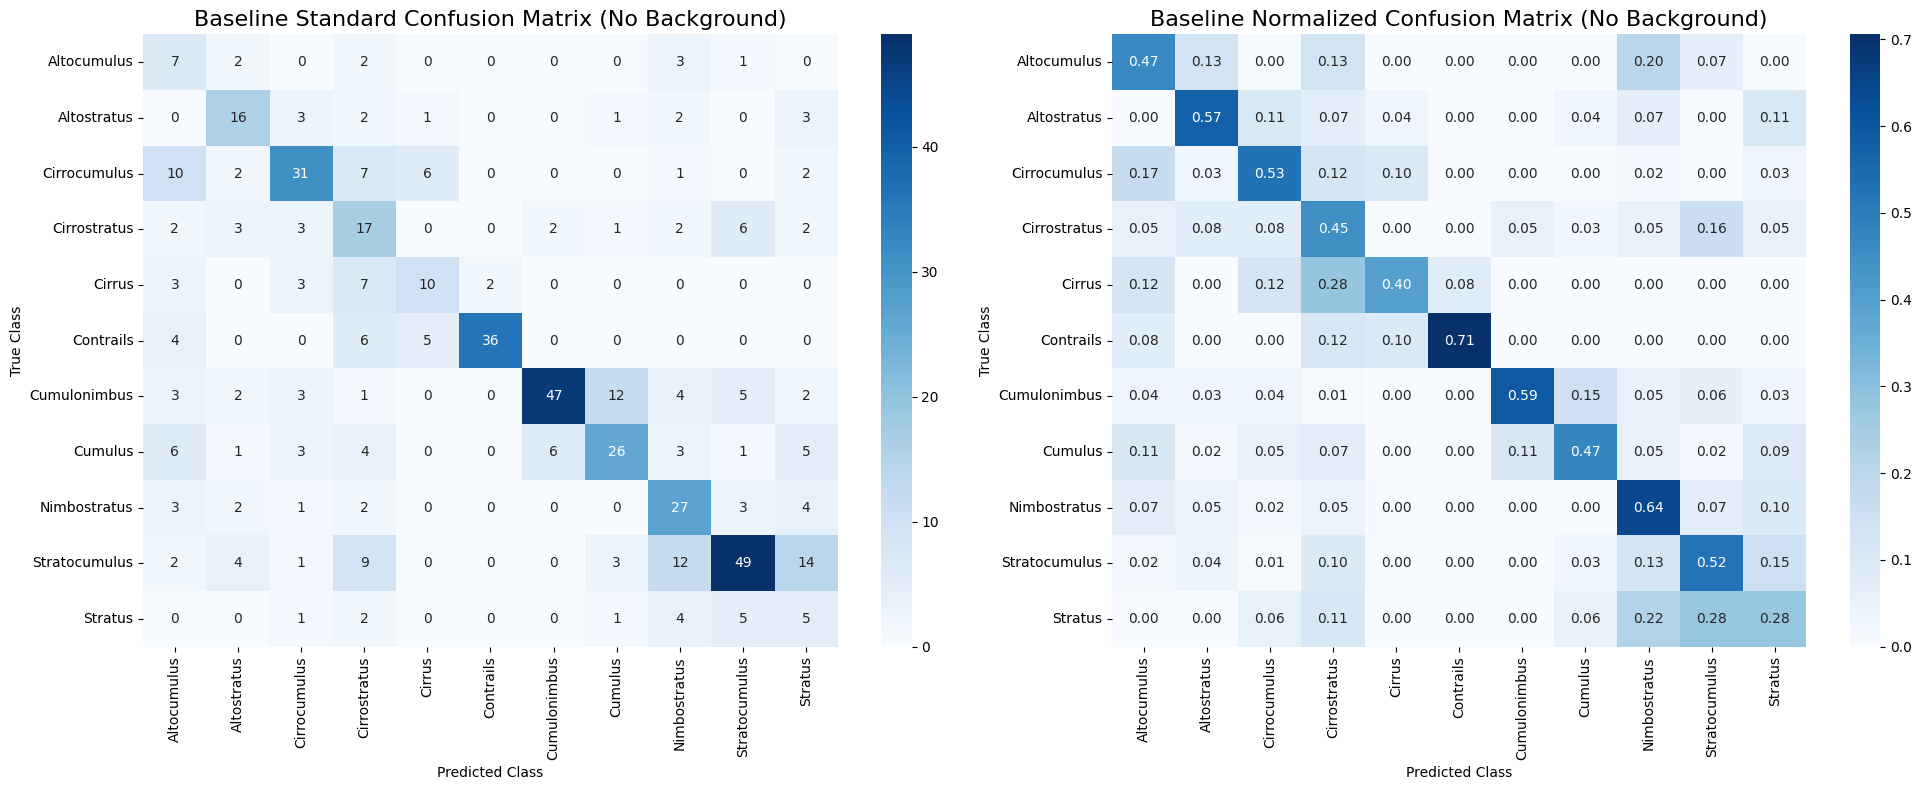

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

# 1. Evaluate performance metrics on the validation dataset
print(f"Evaluating Baseline Model: {baseline_path}\n")
metrics = baseline_model.val(data="config.yaml")

# Calculate Accuracy from the confusion matrix using number of classes
try:
    cm_matrix = metrics.confusion_matrix.matrix
    nc = len(baseline_model.names)
    # Get class-only confusion matrix
    cm_classes = cm_matrix[:nc, :nc]
    # Calculate accuracy as sum of diagonal (TP) divided by all true class instances
    accuracy = np.trace(cm_classes) / cm_matrix[:, :nc].sum() if cm_matrix[:, :nc].sum() > 0 else 0.0
except Exception as e:
    accuracy = 0.0

print("\n--- Overall Baseline Metrics ---")
print("mAP50-95:", round(metrics.box.map, 4))
print("mAP50:", round(metrics.box.map50, 4))
print("Precision:", round(metrics.box.mp, 4))
print("Recall:", round(metrics.box.mr, 4))
print("Accuracy (from Confusion Matrix):", round(accuracy, 4))

print("\n--- Per-Class Performance (mAP50) ---")
for name, m in zip(baseline_model.names.values(), metrics.box.maps):
    print(f"{name:<15}: {round(m, 3)}")

# 2. Plot Custom Confusion Matrices explicitly excluding the background
class_names = list(baseline_model.names.values())

# Normalize the class-only matrix (by row / true label)
cm_normalized = cm_classes.astype('float') / (cm_classes.sum(axis=1)[:, np.newaxis] + 1e-9)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Standard Confusion Matrix
sns.heatmap(cm_classes, annot=True, fmt='.0f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title("Baseline Standard Confusion Matrix (No Background)", fontsize=16)
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("True Class")

# Normalized Confusion Matrix
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title("Baseline Normalized Confusion Matrix (No Background)", fontsize=16)
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("True Class")

plt.tight_layout()
plt.show()


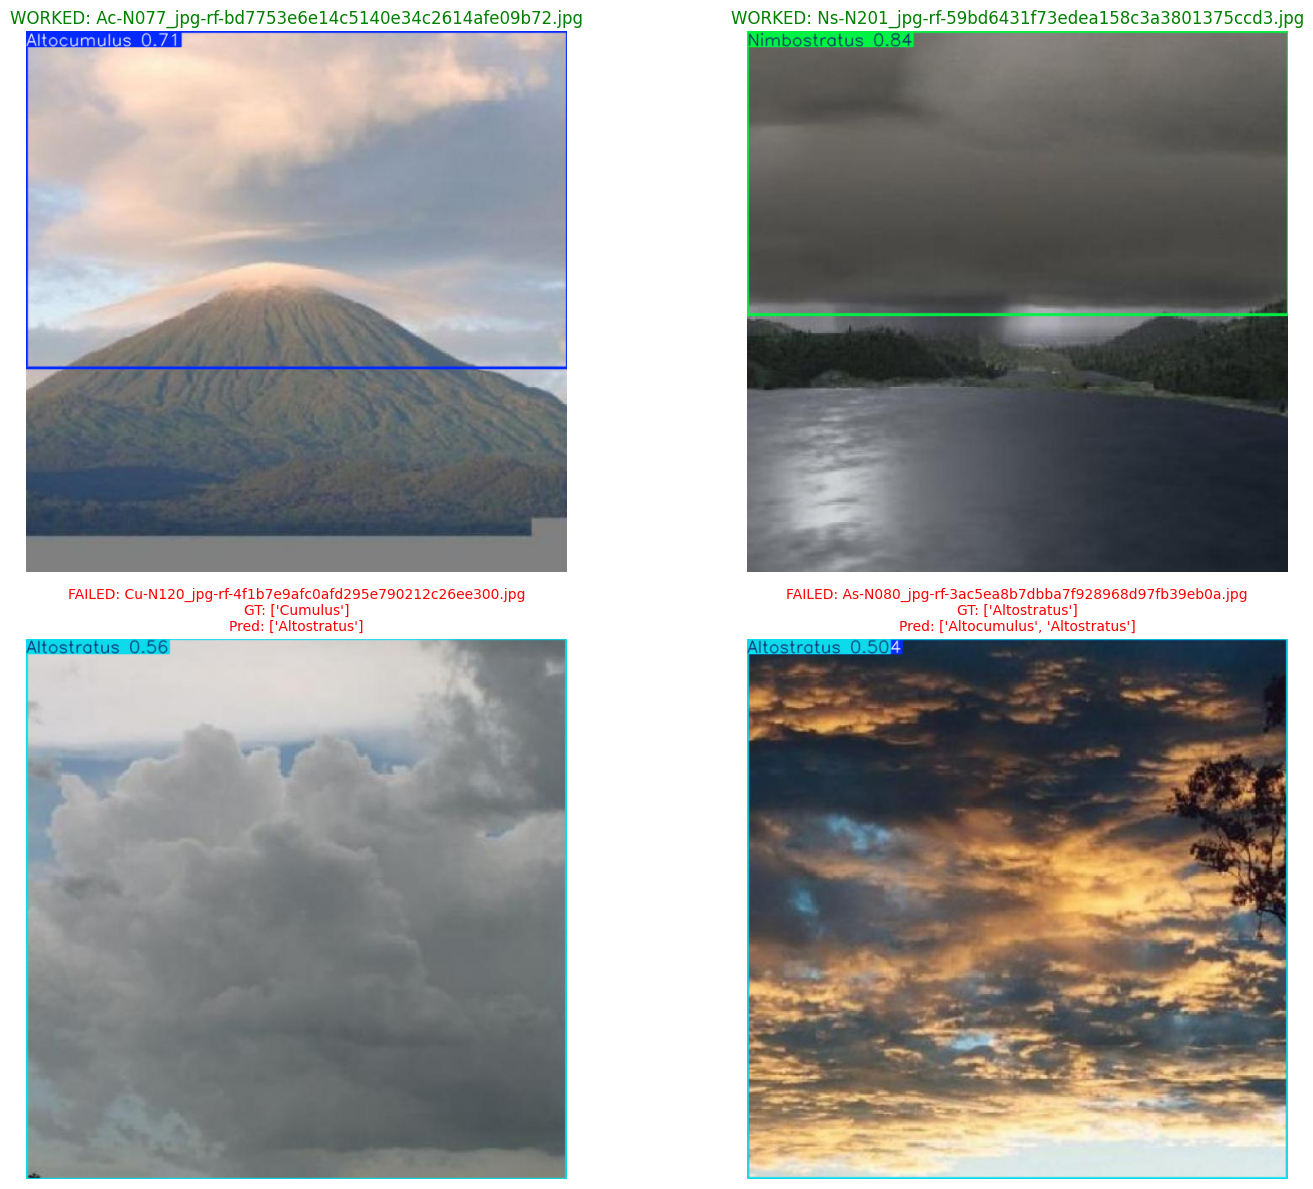

In [ ]:
%matplotlib inline
from ultralytics import YOLO
import matplotlib.pyplot as plt
from PIL import Image
import os
import glob
import random

# 1. Load the champion model
model_path = "/content/drive/MyDrive/IAT 360/runs/fine_tune_box_12.0/weights/best.pt"
model = YOLO(model_path)

# 2. Get validation images and labels
val_images_dir = "All_data/images/val"
val_labels_dir = "All_data/labels/val"
val_img_files = sorted(glob.glob(os.path.join(val_images_dir, "*.jpg")))

worked_examples = []
failed_examples = []

# Run prediction on a subset of validation images to find examples
random.seed(42)
sampled_images = random.sample(val_img_files, min(len(val_img_files), 50))

for img_path in sampled_images:
    base_name = os.path.splitext(os.path.basename(img_path))[0]
    label_path = os.path.join(val_labels_dir, f"{base_name}.txt")

    if not os.path.exists(label_path):
        continue

    # Read ground truth labels
    gt_classes = set()
    with open(label_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if parts:
                gt_classes.add(int(parts[0]))

    # Run prediction
    results = model(img_path, verbose=False)
    pred_classes = set(results[0].boxes.cls.cpu().numpy().astype(int)) if len(results[0].boxes) > 0 else set()

    # Compare sets
    if gt_classes == pred_classes and len(gt_classes) > 0:
        worked_examples.append((img_path, results[0].plot()))
    elif gt_classes != pred_classes:
        failed_examples.append((img_path, results[0].plot(), gt_classes, pred_classes))

# 3. Visualize the results
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot worked examples
for i in range(2):
    if i < len(worked_examples):
        img_path, plotted_img = worked_examples[i]
        axes[0, i].imshow(plotted_img[:, :, ::-1])  # Convert BGR to RGB
        axes[0, i].set_title(f"WORKED: {os.path.basename(img_path)}", color='green', fontsize=12)
    axes[0, i].axis('off')

# Plot failed examples
for i in range(2):
    if i < len(failed_examples):
        img_path, plotted_img, gt, pred = failed_examples[i]
        gt_names = [model.names[g] for g in gt]
        pred_names = [model.names[p] for p in pred]
        axes[1, i].imshow(plotted_img[:, :, ::-1])  # Convert BGR to RGB
        axes[1, i].set_title(f"FAILED: {os.path.basename(img_path)}\nGT: {gt_names}\nPred: {pred_names}", color='red', fontsize=10)
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

# Hyperparameter Evaluation


Make sure you download both of the following files and unzip it to your google drive
* [All_data](https://1sfu-my.sharepoint.com/:u:/r/personal/yya6_sfu_ca/Documents/CV%20Project%20Group%2013/All_data.zip?d=w99f0d6e24789462aa37f4e1b3fae6704&csf=1&web=1&e=5w1wHF)
* [runs](https://1sfu-my.sharepoint.com/:u:/r/personal/yya6_sfu_ca/Documents/CV%20Project%20Group%2013/runs-20261106T030510Z-1-001.zip?d=w74339fa9a015476e8e23f2bc48ba9367&csf=1&web=1&e=ZKJmJJ)

Connect to your Google Drive to load the project files

In [ ]:
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Set your current path to inside the Project folder containing the following:
* The baseline weight located inside `runs/cloud_baseline_result_yolov8s/weights/best.pt` path
* The `All_data` dataset folder
* The config.yaml file (if you don't have this created on your Google Drive, create it using the %%writefile config.yaml
 cell above under the Model Training section)

In [ ]:
%cd "/content/drive/MyDrive/IAT 360" # Ensure you have the correct file structure inside this path, if the check fail, double check your files or paths
import os

# Files to verify
files_to_check = [
    'runs/cloud_baseline_result_yolov8s/weights/best.pt',
    'config.yaml',
    'All_data',
    'All_data/images',
    'All_data/labels'
]

print("=== File Verification Results ===")
for path in files_to_check:
    exists = os.path.exists(path)
    status = "✅ FOUND" if exists else "❌ MISSING"
    print(f"{path:<50} : {status}")

[Errno 2] No such file or directory: '/content/drive/MyDrive/IAT 360 # Ensure you have the correct file structure inside this path, if the check fail, double check your files or paths'
/content/drive/MyDrive/IAT 360
=== File Verification Results ===
runs/cloud_baseline_result_yolov8s/weights/best.pt : ✅ FOUND
config.yaml                                        : ✅ FOUND
All_data                                           : ✅ FOUND
All_data/images                                    : ✅ FOUND
All_data/labels                                    : ✅ FOUND


In [ ]:
import pandas as pd
from ultralytics import YOLO
import os

# 1. Base weights path to start training from
base_weights = 'yolov8s.pt'

# 2. Define box loss gain values to evaluate (including baseline 7.5)
box_values = [3.0, 7.5, 12.0, 20.0]
results_list = []

# 3. Fine-tune and evaluate each box hyperparameter
for box_val in box_values:
    print(f"\n{'='*60}\nFine-Tuning with Box Loss Weight (box) = {box_val}\n{'='*60}")

    # Re-initialize from the baseline weights for a fair baseline starting point
    model = YOLO(base_weights)

    # Train for 15 epochs (warmup is 3 epochs, leaving 12 epochs for active testing)
    model.train(
        data="config.yaml",
        epochs=15,                                                    # 15 epochs budget per option
        patience=10,                                                  # Safe patience setting
        batch=16,                                                  # Matches baseline batch size
        imgsz=640,                                                 # Matched baseline image size
        box=box_val,                                                  # The hyperparameter being evaluated
        project="/content/drive/MyDrive/IAT 360/runs",                 # Output path
        name=f"fine_tune_box_{box_val}",                               # Saved folders avoiding overwrites
        cache=True,                                                   # Faster caching on Drive
        verbose=False
    )

    # Evaluate the performance metrics using validation split
    print(f"Evaluating fine-tuned model (box={box_val}) on validation set...")
    metrics = model.val(data="config.yaml", split="val", verbose=False)

    results_list.append({
        "Box Loss Gain (box)": "7.5 (Baseline)" if box_val == 7.5 else str(box_val),
        "Precision": round(metrics.box.mp, 4),
        "Recall": round(metrics.box.mr, 4),
        "mAP50": round(metrics.box.map50, 4),
        "mAP50-95": round(metrics.box.map, 4)
    })

# 4. Display comparison table to pick your final candidate winner
df_results = pd.DataFrame(results_list)
display(df_results)


Fine-Tuning with Box Loss Weight (box) = 3.0
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=3.0, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=config.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fine_tune_box_3.0, nbs=64, nms=N

,Box Loss Gain (box),Precision,Recall,mAP50,mAP50-95
0,3.0,0.4391,0.5923,0.5114,0.4474
1,7.5 (Baseline),0.4188,0.6437,0.5057,0.4457
2,12.0,0.4284,0.5908,0.5140,0.4508
3,20.0,0.4127,0.6221,0.5114,0.4525


### Hyperparmeter Result Metrics

In [ ]:

import numpy as np, pandas as pd
from ultralytics import YOLO

CONFIG = "config.yaml"
RUNS = "runs"

# ← each person: put your run folders here (label: folder)
MODELS = {
    "Box 3.0": f"{RUNS}/fine_tune_box_3.0",
    "Box 7.5": f"{RUNS}/fine_tune_box_7.5",
    "Box 12.0": f"{RUNS}/fine_tune_box_12.0",
    "Box 20.0": f"{RUNS}/fine_tune_box_20.0",
}

rows = []
for label, folder in MODELS.items():
    m = YOLO(f"{folder}/weights/best.pt")      # loads the trained model, no training
    nc = len(m.names)
    for split in ["val", "test"]:
        r = m.val(data=CONFIG, split=split, project=RUNS, verbose=False,
                  name=f"eval_{folder.split('/')[-1]}_{split}", exist_ok=True)
        p, rc = r.box.mp, r.box.mr
        cm = r.confusion_matrix.matrix          # rows = predicted, cols = true, last = background
        acc = np.trace(cm[:nc, :nc]) / cm[:, :nc].sum()
        rows.append({"model": label, "split": split,
                     "precision": round(p, 3), "recall": round(rc, 3),
                     "F1": round(2 * p * rc / (p + rc + 1e-9), 3),
                     "accuracy": round(acc, 3),
                     "mAP50": round(r.box.map50, 3), "mAP50-95": round(r.box.map, 3)})

pd.DataFrame(rows).sort_values(by=["mAP50", "mAP50-95"], ascending=False)


Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 72 layers, 11,129,841 parameters, 0 gradients, 28.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.2±0.0 ms, read: 34.1±12.7 MB/s, size: 23.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/IAT 360/All_data/labels/val.cache... 505 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 505/505 105.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 5.6it/s 5.7s
                   all        505        507      0.439      0.592      0.511      0.447
Speed: 0.7ms preprocess, 4.2ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /content/drive/MyDrive/IAT 360/runs/detect/runs/eval_fine_tune_box_3.0_val
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu1

,model,split,precision,recall,F1,accuracy,mAP50,mAP50-95
4,Box 12.0,val,0.428,0.591,0.497,0.538,0.514,0.451
6,Box 20.0,val,0.413,0.622,0.496,0.540,0.511,0.453
0,Box 3.0,val,0.439,0.592,0.504,0.533,0.511,0.447
2,Box 7.5,val,0.419,0.644,0.507,0.515,0.506,0.446
3,Box 7.5,test,0.201,0.220,0.210,0.184,0.122,0.066
7,Box 20.0,test,0.182,0.172,0.177,0.163,0.111,0.056
5,Box 12.0,test,0.175,0.234,0.200,0.153,0.109,0.061
1,Box 3.0,test,0.133,0.256,0.175,0.163,0.093,0.048


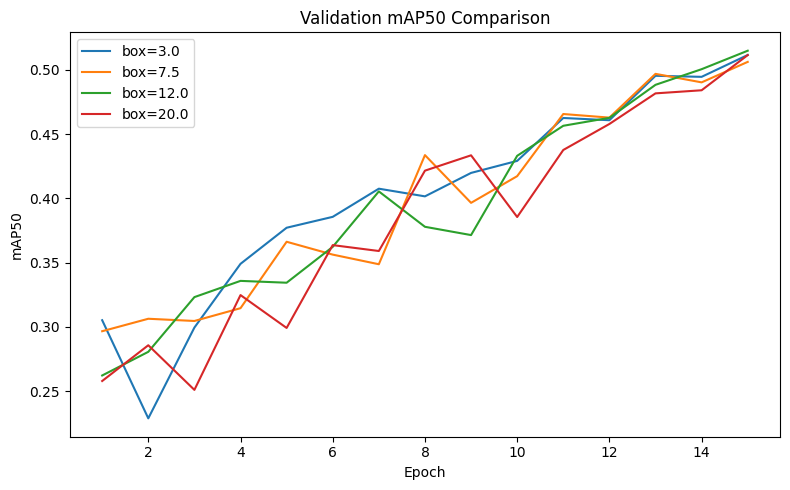

,box,best epoch,precision,recall,F1,mAP50,mAP50-95
2,12.0,15,0.428,0.591,0.497,0.515,0.452
0,3.0,15,0.439,0.592,0.504,0.512,0.447
3,20.0,15,0.414,0.623,0.497,0.512,0.453
1,7.5 (Baseline),15,0.418,0.646,0.508,0.506,0.446


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import numpy as np

RUNS = "runs"
BOXES = [3.0, 7.5, 12.0, 20.0]

rows = []
fig, ax = plt.subplots(figsize=(8, 5))

for box_val in BOXES:
    run_path = f"{RUNS}/fine_tune_box_{box_val}/results.csv"
    if not os.path.exists(run_path):
        print(f"Warning: Results file not found for box={box_val} at {run_path}")
        continue

    df = pd.read_csv(run_path)
    df.columns = df.columns.str.strip()

    best = df.loc[df["metrics/mAP50(B)"].idxmax()]
    p, r = best["metrics/precision(B)"], best["metrics/recall(B)"]

    f1 = 2 * p * r / (p + r + 1e-9)

    rows.append({
        "box": "7.5 (Baseline)" if box_val == 7.5 else str(box_val),
        "best epoch": int(best["epoch"]),
        "precision": round(p, 3),
        "recall": round(r, 3),
        "F1": round(f1, 3),
        "mAP50": round(best["metrics/mAP50(B)"], 3),
        "mAP50-95": round(best["metrics/mAP50-95(B)"], 3)
    })

    ax.plot(df["epoch"], df["metrics/mAP50(B)"], label=f"box={box_val}")

ax.set_title("Validation mAP50 Comparison")
ax.set_xlabel("Epoch")
ax.set_ylabel("mAP50")
ax.legend()

plt.tight_layout()
plt.show()

coarse_box = pd.DataFrame(rows).sort_values("mAP50", ascending=False)
display(coarse_box)


## Re-train the model with Best Hyperparameters from each member

Train a new model with the best value from each hyperparameter below
* weight_decay = 0.05
* optimizer = adam
* box = 12.0
* lr0 = 0.0001

In [ ]:
%ls
%cd "drive/MyDrive/IAT 360"

drive/  sample_data/
/content/drive/MyDrive/IAT 360


In [ ]:
from ultralytics import YOLO

# 1. Initialize a clean YOLOv8s pretrained model
model = YOLO('yolov8s.pt')

# 2. Train the model using the collective best hyperparameters
model.train(
    data="config.yaml",
    epochs=50,                                                    # Standard final epoch count
    patience=10,                                                  # Early-stopping patience
    batch=16,                                                     # Matches base configuration batch size
    device=0,                                                     # Runs on Tesla T4 GPU
    optimizer="Adam",                                             # Chosen optimizer
    lr0=0.0001,                                                   # Optimized learning rate
    box=12.0,                                                     # Optimized box loss gain
    weight_decay=0.05,                                            # Optimized weight decay
    project="/content/drive/MyDrive/IAT 360/runs",                 # Keep runs organized inside Drive
    name="final_combined_yolov8s",                                # Distinctive name for final run
    cache=True                                                    # Faster RAM caching
)

Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=12.0, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=config.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=final_combined_yolov8s, nbs=64, nms=None, opset=None, optimize=False, opti

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d0566d37af0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.

## Comparison bewteen Combined Optimal Hyperparameter model v.s. Baseline model

Evaluating Original Baseline to calculate accuracy...
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 72 layers, 11,129,841 parameters, 0 gradients, 28.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.3±0.1 ms, read: 36.3±10.8 MB/s, size: 27.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/IAT 360/All_data/labels/val.cache... 505 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 505/505 151.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 5.4it/s 5.9s
                   all        505        507      0.439      0.607      0.536      0.468
Speed: 0.7ms preprocess, 4.2ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /content/drive/MyDrive/IAT 360/runs/detect/val
Evaluating Optimized Combin

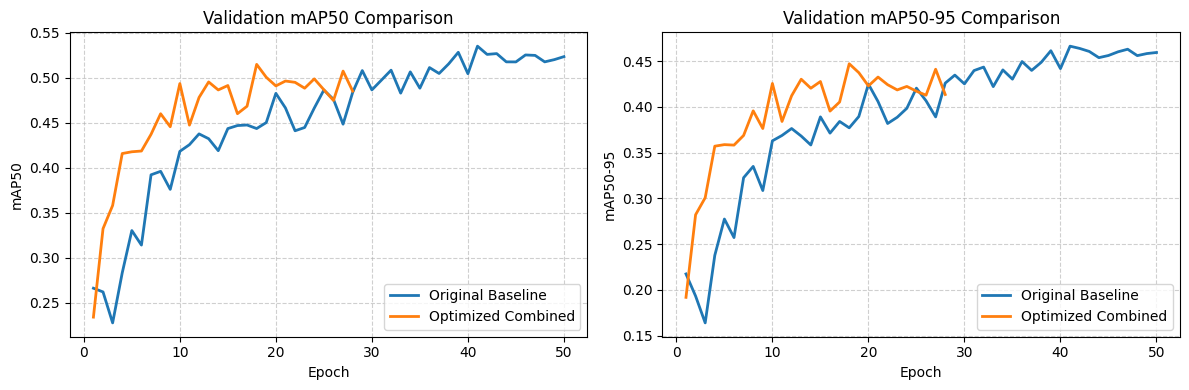

,Model Run,Best Epoch,Precision (val),Recall (val),F1-Score (val),Accuracy (val),mAP50 (val),mAP50-95 (val)
0,Original Baseline,41,0.4378,0.6070,0.5087,0.5345,0.5352,0.4663
1,Optimized Combined,18,0.4472,0.5622,0.4981,0.5010,0.5150,0.4471


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
from ultralytics import YOLO

# Paths to the results
baseline_dir = "runs/cloud_baseline_result_yolov8s"
combined_dir = "runs/final_combined_yolov8s"
config_path = "config.yaml"

models_to_eval = [
    ("Original Baseline", baseline_dir),
    ("Optimized Combined", combined_dir)
]

summary_data = []
dfs = {}

for label, folder in models_to_eval:
    csv_path = os.path.join(folder, "results.csv")
    weights_path = os.path.join(folder, "weights", "best.pt")

    if not os.path.exists(csv_path):
        print(f"Error: Results file not found at: {csv_path}")
        continue
    if not os.path.exists(weights_path):
        print(f"Error: Weights file not found at: {weights_path}")
        continue

    # Load dataset
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()
    dfs[label] = df

    # Extract best metrics according to validation mAP50
    best_row = df.loc[df["metrics/mAP50(B)"].idxmax()]
    p = best_row["metrics/precision(B)"]
    r = best_row["metrics/recall(B)"]
    f1 = 2 * p * r / (p + r + 1e-9)

    # Calculate accuracy using YOLO model confusion matrix
    print(f"Evaluating {label} to calculate accuracy...")
    m = YOLO(weights_path)
    nc = len(m.names)
    res = m.val(data=config_path, split="val", verbose=False, exist_ok=True)
    cm = res.confusion_matrix.matrix
    acc = np.trace(cm[:nc, :nc]) / cm[:, :nc].sum() if cm[:, :nc].sum() > 0 else 0.0

    summary_data.append({
        "Model Run": label,
        "Best Epoch": int(best_row["epoch"]),
        "Precision (val)": round(p, 4),
        "Recall (val)": round(r, 4),
        "F1-Score (val)": round(f1, 4),
        "Accuracy (val)": round(acc, 4),
        "mAP50 (val)": round(best_row["metrics/mAP50(B)"], 4),
        "mAP50-95 (val)": round(best_row["metrics/mAP50-95(B)"], 4)
    })

if summary_data:
    df_comparison = pd.DataFrame(summary_data)

    # Setup side-by-side plots for mAP50 and mAP50-95
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    colors = {"Original Baseline": "tab:blue", "Optimized Combined": "tab:orange"}

    # Plot 1: Validation mAP50 Curves
    for label in dfs:
        df = dfs[label]
        axes[0].plot(df["epoch"], df["metrics/mAP50(B)"], label=label, color=colors[label], linewidth=2)
    axes[0].set_title("Validation mAP50 Comparison")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("mAP50")
    axes[0].grid(True, linestyle="--", alpha=0.6)
    axes[0].legend()

    # Plot 2: Validation mAP50-95 Curves
    for label in dfs:
        df = dfs[label]
        axes[1].plot(df["epoch"], df["metrics/mAP50-95(B)"], label=label, color=colors[label], linewidth=2)
    axes[1].set_title("Validation mAP50-95 Comparison")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("mAP50-95")
    axes[1].grid(True, linestyle="--", alpha=0.6)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    # Display comparison summary
    display(df_comparison)


# Final Model Evaluation

Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 72 layers, 11,129,841 parameters, 0 gradients, 28.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.2±0.0 ms, read: 34.8±13.0 MB/s, size: 26.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/IAT 360/All_data/labels/val.cache... 505 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 505/505 100.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 5.3it/s 6.0s
                   all        505        507      0.439      0.607      0.536      0.468
Speed: 0.8ms preprocess, 4.2ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to /content/drive/MyDrive/IAT 360/runs/detect/runs/val
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 2

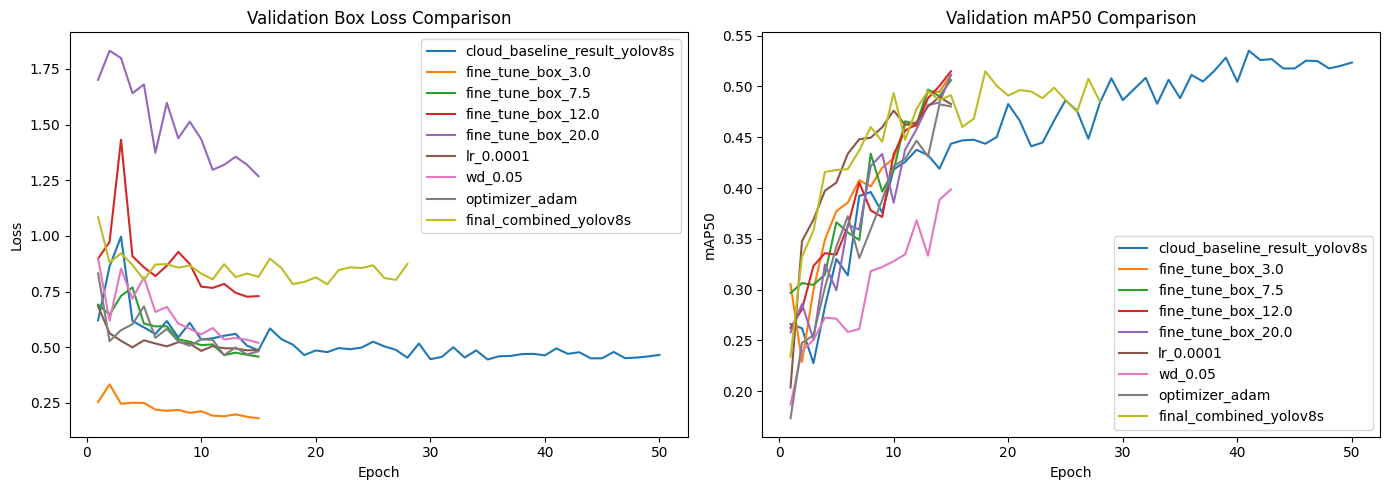

=== All Detected Runs Ranked by mAP50 ===


,Run Name,best epoch,precision,recall,F1,accuracy,mAP50,mAP50-95,Weight Path,Status
0,cloud_baseline_result_yolov8s,41,0.438,0.607,0.509,0.535,0.535,0.466,runs/cloud_baseline_result_yolov8s/weights/bes...,✅ EXISTS
3,fine_tune_box_12.0,15,0.428,0.591,0.497,0.538,0.515,0.452,runs/fine_tune_box_12.0/weights/best.pt,✅ EXISTS
8,final_combined_yolov8s,18,0.447,0.562,0.498,0.501,0.515,0.447,runs/final_combined_yolov8s/weights/best.pt,✅ EXISTS
4,fine_tune_box_20.0,15,0.414,0.623,0.497,0.540,0.512,0.453,runs/fine_tune_box_20.0/weights/best.pt,✅ EXISTS
1,fine_tune_box_3.0,15,0.439,0.592,0.504,0.533,0.512,0.447,runs/fine_tune_box_3.0/weights/best.pt,✅ EXISTS
2,fine_tune_box_7.5,15,0.418,0.646,0.508,0.515,0.506,0.446,runs/fine_tune_box_7.5/weights/best.pt,✅ EXISTS
5,lr_0.0001,14,0.390,0.603,0.474,0.515,0.490,0.425,runs/lr_0.0001/weights/best.pt,✅ EXISTS
7,optimizer_adam,14,0.391,0.584,0.468,0.497,0.482,0.425,runs/optimizer_adam/weights/best.pt,✅ EXISTS
6,wd_0.05,15,0.329,0.548,0.411,0.467,0.399,0.340,runs/wd_0.05/weights/best.pt,✅ EXISTS


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import numpy as np
from ultralytics import YOLO

runs_dir = "runs"
runs_found = []

# Traverse the runs folder looking for results.csv
for root, dirs, files in os.walk(runs_dir):
    if "results.csv" in files:
        results_path = os.path.join(root, "results.csv")
        try:
            df = pd.read_csv(results_path)
            df.columns = df.columns.str.strip()

            if "metrics/mAP50(B)" in df.columns:
                best_epoch_row = df.loc[df["metrics/mAP50(B)"].idxmax()]
                best_map50 = best_epoch_row["metrics/mAP50(B)"]
                best_epoch = best_epoch_row["epoch"]
                p = best_epoch_row["metrics/precision(B)"]
                r = best_epoch_row["metrics/recall(B)"]
                f1 = 2 * p * r / (p + r + 1e-9)

                # Check if best weights file actually exists
                weights_path = os.path.join(root, "weights", "best.pt")
                exists_status = "✅ EXISTS" if os.path.exists(weights_path) else "❌ MISSING"

                # Calculate exact accuracy using the model's confusion matrix
                accuracy = 0.0
                if os.path.exists(weights_path):
                    m = YOLO(weights_path)
                    nc = len(m.names)
                    res = m.val(data="config.yaml", split="val", project=runs_dir, verbose=False, exist_ok=True)
                    cm = res.confusion_matrix.matrix
                    if cm[:, :nc].sum() > 0:
                        accuracy = np.trace(cm[:nc, :nc]) / cm[:, :nc].sum()

                runs_found.append({
                    "Run Name": os.path.basename(root),
                    "best epoch": int(best_epoch),
                    "precision": round(p, 3),
                    "recall": round(r, 3),
                    "F1": round(f1, 3),
                    "accuracy": round(accuracy, 3),
                    "mAP50": round(best_map50, 3),
                    "mAP50-95": round(best_epoch_row["metrics/mAP50-95(B)"], 3),
                    "Weight Path": weights_path,
                    "Status": exists_status,
                    "df": df
                })
        except Exception as e:
            print(f"Error reading {results_path}: {e}")

# Sort runs by highest mAP50 performance
if runs_found:
    df_runs = pd.DataFrame(runs_found).sort_values(by="mAP50", ascending=False)
    best_run = df_runs.iloc[0]

    print("\n🏆 CHAMPION MODEL FOUND:")
    print(f"- Run Name   : {best_run['Run Name']}")
    print(f"- Best mAP50 : {best_run['mAP50']}")
    print(f"- Best Epoch : {best_run['best epoch']}")
    print(f"- File Path  : {best_run['Weight Path']}")
    print(f"- Status     : {best_run['Status']}\n")

    # Generate side-by-side plots for all detected runs
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for run in runs_found:
        df = run["df"]
        label = run["Run Name"]
        axes[0].plot(df["epoch"], df["val/box_loss"], label=label)
        axes[1].plot(df["epoch"], df["metrics/mAP50(B)"], label=label)

    axes[0].set_title("Validation Box Loss Comparison")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].set_title("Validation mAP50 Comparison")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("mAP50")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    print("=== All Detected Runs Ranked by mAP50 ===")
    # Drop the df reference from dataframe display to keep output clean
    display(df_runs.drop(columns=["df"]))
else:
    print("No valid training result files (results.csv) were found in the specified runs directory.")

In [ ]:
from ultralytics import YOLO
import numpy as np

# Loaded the detected champion model weights
best_path = "runs/cloud_baseline_result_yolov8s/weights/best.pt"
best = YOLO(best_path)

print(f"Evaluating Champion Model: {best_path}\n")
metrics = best.val(data="config.yaml")

# Calculate Accuracy from the confusion matrix using number of classes
try:
    cm_matrix = metrics.confusion_matrix.matrix
    nc = len(best.names)
    accuracy = np.trace(cm_matrix[:nc, :nc]) / cm_matrix[:, :nc].sum() if cm_matrix[:, :nc].sum() > 0 else 0.0
except Exception as e:
    accuracy = 0.0

print("\n--- Overall Metrics ---")
print("mAP50-95:", round(metrics.box.map, 4))
print("mAP50:", round(metrics.box.map50, 4))
print("Precision:", round(metrics.box.mp, 4))
print("Recall:", round(metrics.box.mr, 4))
print("Accuracy (from Confusion Matrix):", round(accuracy, 4))

print("\n--- Per-Class Performance (mAP50) ---")
for name, m in zip(best.names.values(), metrics.box.maps):
    print(f"{name:<15}: {round(m, 3)}")


Evaluating Champion Model: runs/cloud_baseline_result_yolov8s/weights/best.pt

Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 72 layers, 11,129,841 parameters, 0 gradients, 28.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.2±0.0 ms, read: 43.3±13.1 MB/s, size: 29.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/IAT 360/All_data/labels/val.cache... 505 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 505/505 92.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 5.5it/s 5.9s
                   all        505        507      0.439      0.607      0.536      0.468
           Altocumulus         40         40      0.352        0.4       0.38      0.349
           Altostratus         32         32      0.427     

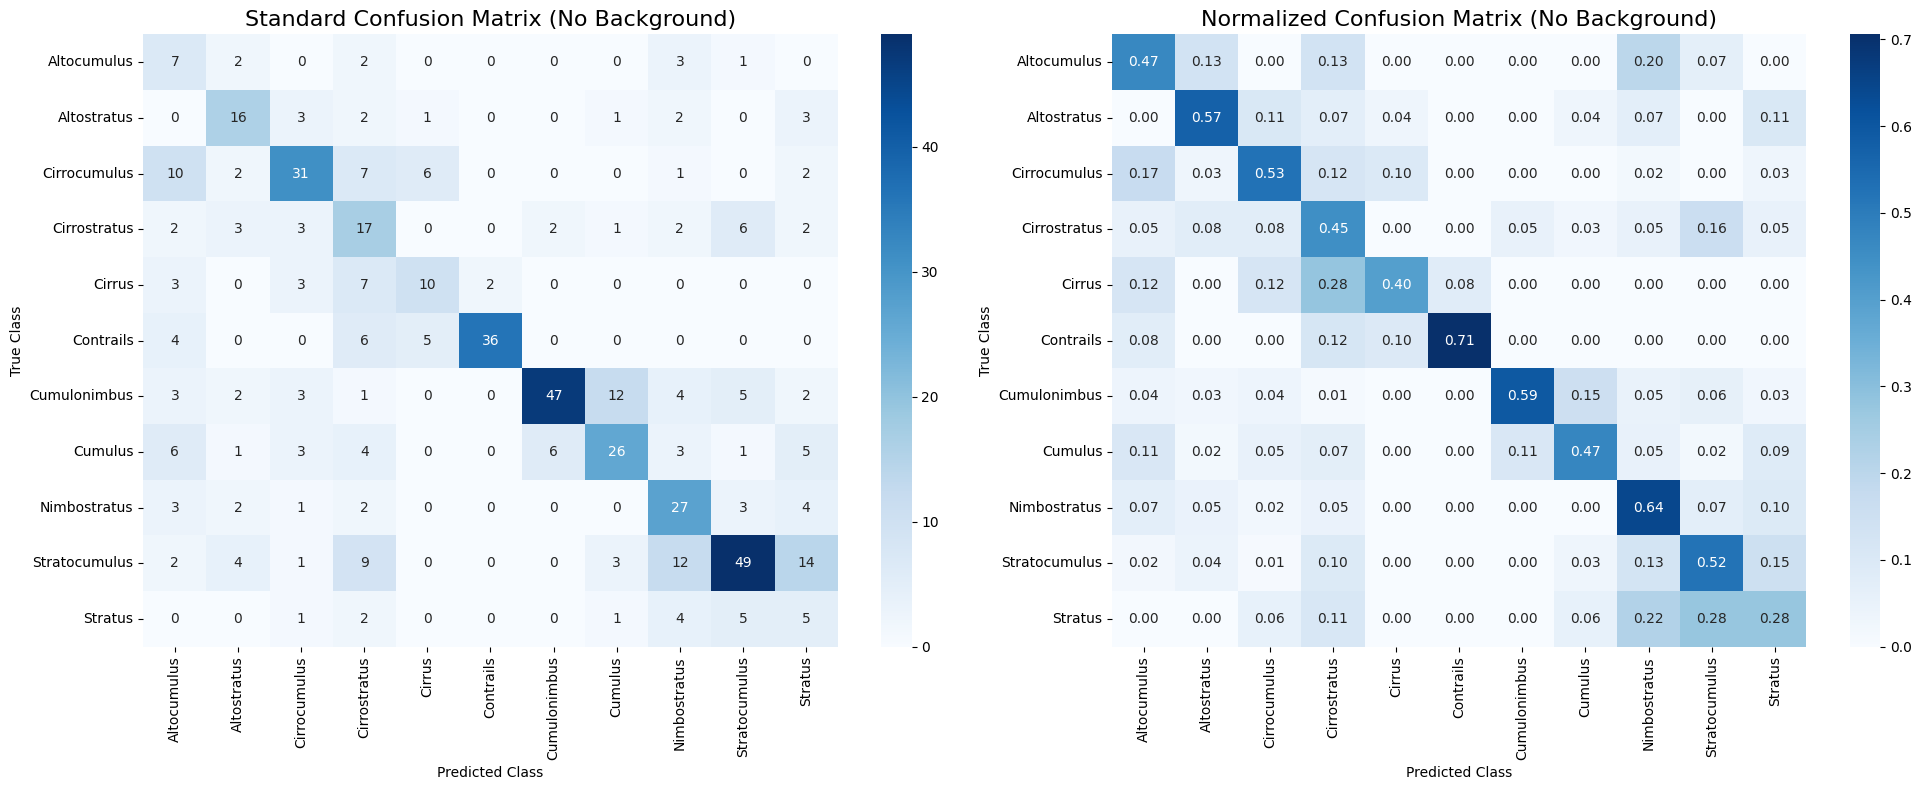

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

try:
    # Get the raw confusion matrix from the metrics calculated in the previous cell
    cm_matrix = metrics.confusion_matrix.matrix
    nc = len(best.names)
    class_names = list(best.names.values())

    # Slice the matrix to exclude the background (which is typically the last row/column)
    cm_classes = cm_matrix[:nc, :nc]

    # Normalize by the true class (row sum)
    cm_normalized = cm_classes.astype('float') / (cm_classes.sum(axis=1)[:, np.newaxis] + 1e-9)

    # Create side-by-side visualization
    fig, axes = plt.subplots(1, 2, figsize=(20, 8))

    # Plot Standard Confusion Matrix (No Background)
    sns.heatmap(cm_classes, annot=True, fmt='.0f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title("Standard Confusion Matrix (No Background)", fontsize=16)
    axes[0].set_xlabel("Predicted Class")
    axes[0].set_ylabel("True Class")

    # Plot Normalized Confusion Matrix (No Background)
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[1])
    axes[1].set_title("Normalized Confusion Matrix (No Background)", fontsize=16)
    axes[1].set_xlabel("Predicted Class")
    axes[1].set_ylabel("True Class")

    plt.tight_layout()
    plt.show()

except NameError:
    print("Please run the previous evaluation cell first to load the 'metrics' and 'best' model variables.")